# Hanging-Sphere Cut-Cell Convergence

This notebook is the canonical, checkpointed convergence workflow for the hanging sphere. It compares four stiffness frameworks on the same active support:

1. Naive full-cell Gauss stiffness on cut cells.
2. Geometric-volume-fraction-weighted full-cell Gauss stiffness.
3. QuESo quadrature stiffness.
4. NN cut-cell hybrid stiffness.

All frameworks use the same material, gravity, QuESo-derived cut-cell force, and a plane-only nested hard constraint at $z=6.75$. Each lower-resolution solution is interpolated to its framework's own $256^3$ reference before global and near-surface errors are measured. Existing checkpoints are never overwritten; expensive solves are explicitly opt-in.

In [ ]:
from pathlib import Path
import gc
import os
import sys
import time

import numpy as np
import pandas as pd
import torch

root = Path.cwd().resolve()
while root != root.parent and not (root / 'clean_simulation').exists():
    root = root.parent
if not (root / 'clean_simulation').exists():
    raise RuntimeError('Run this notebook from the repository root or a descendant directory.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# Set these environment variables on AWS before starting Jupyter; defaults are safe locally.
OUTPUT_DIR = Path(os.environ.get(
    'HANGING_SPHERE_OUTPUT_DIR',
    root / 'clean_simulation' / 'outputs' / 'sphere_displacement_convergence',
)).expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SOLVE_DEVICE = os.environ.get('HANGING_SPHERE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu')
CPU_THREADS = int(os.environ.get('HANGING_SPHERE_CPU_THREADS', min(6, os.cpu_count() or 1)))
RESOLUTION_SCHEDULE = tuple(int(value) for value in os.environ.get(
    'HANGING_SPHERE_RESOLUTIONS', '8,16,32,64,128,256',
).split(','))
REFERENCE_RESOLUTION = int(os.environ.get('HANGING_SPHERE_REFERENCE_RESOLUTION', '256'))
RUN_SOLVES = os.environ.get('HANGING_SPHERE_RUN_SOLVES', '0') == '1'
CG_MAX_ITER = int(os.environ.get('HANGING_SPHERE_CG_MAX_ITER', '4000'))

if SOLVE_DEVICE == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('HANGING_SPHERE_DEVICE=cuda was requested but CUDA is unavailable.')
torch.set_num_threads(CPU_THREADS)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

queso_python_path = root / 'QuESo' / 'out' / 'install' / ('win' if os.name == 'nt' else 'linux')
if queso_python_path.exists() and str(queso_python_path) not in sys.path:
    sys.path.insert(0, str(queso_python_path))
if os.name == 'nt' and hasattr(os, 'add_dll_directory') and queso_python_path.exists():
    os.add_dll_directory(str(queso_python_path))

from clean_simulation.bootstrap import configure_legacy_imports
configure_legacy_imports(root)

from clean_simulation.case import build_case_from_stl
from clean_simulation.internal_fem_kernel.runtime.assembly_ops import assemble_force_base
from clean_simulation.internal_fem_kernel.runtime.matrix_free import (
    StructuredCompressedMatrixFreeElasticityOperator,
    solve_matrix_free_cg,
)
from clean_simulation.internal_nn_runtime.cutcell_bridge import compute_nn_cutcell_stiffness, prepare_nn_inputs
from clean_simulation.nn_runtime import load_nn_engine
from internal_fem_kernel.assembly.stiffness import StiffnessAssembly
from internal_fem_kernel.core.grid_indexing import active_element_nodes

FRAMEWORKS = {
    'naive': 'Naive full-cell Gauss',
    'weighted': 'Geometric-volume-fraction weighted Gauss',
    'queso': 'QuESo quadrature',
    'nn': 'NN-cut-cell hybrid',
}
FRAMEWORK_COLORS = {'naive': '#b94732', 'weighted': '#c98b1b', 'queso': '#247b74', 'nn': '#315c99'}
PLANAR_CAP_OUTPUT_DIR = OUTPUT_DIR / 'planar_cap_plane_hard_constraints'
PLANAR_CAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NN_CHECKPOINT = root / 'clean_simulation' / 'outputs' / 'checkpoints' / 'source_sdf_rebuilt_queso_d10_f1024_all_crystals_10h.pt'

SPHERE_OVERRIDES = {
    'grid': {'bounds': [[-9.0, -9.0, -9.0], [9.0, 9.0, 9.0]]},
    'material': {'E': 1.0e6, 'nu': 0.3, 'density': 1.0},
    'integration': {'poly_order': 1, 'gauss_order': 2, 'moment_fitting_residual': 1.0e-8},
    'loads': {'gravity': [0.0, 0.0, -98.1]},
    'bc': {'top_cap_fraction': 0.05, 'constraint_axis': 2, 'constraint_side': 'max'},
}

print(f'Repository root: {root}')
print(f'Output directory: {OUTPUT_DIR}')
print(f'Device: {SOLVE_DEVICE}; CPU threads: {torch.get_num_threads()}; run solves: {RUN_SOLVES}')
if torch.cuda.is_available():
    print(f'CUDA: {torch.cuda.get_device_name(0)}; memory={torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB')

PyTorch CPU threads: 6 (physical-core cap for bandwidth-bound matrix-free work)
Four-framework hanging-sphere displacement study: (8, 16, 32, 64) -> 128^3 reference
Frameworks: Naive full-cell Gauss, Geometric-volume-fraction weighted Gauss, QuESo quadrature, NN-cut-cell hybrid


In [7]:
# QuESo emits [x, y, z, weight]. Normalized coordinates use weights on [0, 1]^3,
# so consumers must apply the physical-domain determinant exactly once.
def point_cell_indices_and_weights(case, point_mask=None):
    points = torch.as_tensor(np.asarray(case.ips), dtype=torch.float64)
    if point_mask is not None:
        points = points[torch.as_tensor(point_mask, dtype=torch.bool)]
    coordinates = points[:, :3]
    weights = points[:, 3]
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    upper = torch.as_tensor(case.grid.bounds[1], dtype=torch.float64)
    normalized = coordinates.numel() and bool(torch.all((coordinates >= 0.0) & (coordinates <= 1.0)))
    if normalized:
        coordinates = lower + coordinates * (upper - lower)
        weights = weights * torch.prod(upper - lower)
    resolution = torch.as_tensor(case.grid.resolution, dtype=torch.int64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    ijk = torch.floor((coordinates - lower) / spacing).to(torch.int64)
    ijk = torch.minimum(torch.maximum(ijk, torch.zeros_like(ijk)), resolution - 1)
    indices = ijk[:, 0] * (resolution[1] * resolution[2]) + ijk[:, 1] * resolution[2] + ijk[:, 2]
    return indices, weights


def physical_cell_weights(case):
    cell_count = int(np.prod(case.grid.resolution))
    indices, weights = point_cell_indices_and_weights(case)
    if not len(indices):
        return torch.zeros(cell_count, dtype=torch.float64)
    volumes = torch.bincount(indices, weights=weights, minlength=cell_count)
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    return (volumes / cell_volume).clamp(0.0, 1.0)


def report_cut_volume_fractions(case, cut_indices):
    fractions = physical_cell_weights(case)[cut_indices]
    if not bool(torch.isfinite(fractions).all()):
        raise RuntimeError('Cut-cell volume fractions contain non-finite values.')
    print(
        f'Cut-cell volume fractions: min={fractions.min():.6g}; '
        f'median={fractions.median():.6g}; mean={fractions.mean():.6g}; max={fractions.max():.6g}'
    )
    return fractions


print('Loaded authoritative physical QuESo point and volume-fraction helpers.')

Loaded point_cell_indices(), point_cell_indices_and_weights(), and physical_cell_weights().


In [ ]:
def phase(message, started_at=None):
    elapsed = '' if started_at is None else f' [{time.perf_counter() - started_at:.1f}s]'
    print(f'[hanging-sphere] {message}{elapsed}', flush=True)


def active_node_ids(active_cells, resolution):
    cells = np.asarray(active_cells, dtype=np.int64)
    node_side = resolution + 1
    i = cells // (resolution * resolution)
    j = (cells // resolution) % resolution
    k = cells % resolution
    base = (i * node_side + j) * node_side + k
    offsets = np.array((0, node_side * node_side, node_side * node_side + node_side, node_side, 1,
                        node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1))
    return np.unique((base[:, None] + offsets).reshape(-1))


def strict_sphere_full_cells(case):
    nx, ny, nz = map(int, case.grid.resolution)
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius_squared = float(sphere['radius']) ** 2
    lower = np.asarray(case.grid.bounds[0], dtype=np.float64)
    spacing = np.asarray((case.grid.dx, case.grid.dy, case.grid.dz), dtype=np.float64)
    y = lower[1] + np.arange(ny + 1) * spacing[1]
    z = lower[2] + np.arange(nz + 1) * spacing[2]
    yy, zz = np.meshgrid(y, z, indexing='ij')
    slabs = []
    for i in range(nx):
        x0 = lower[0] + i * spacing[0]
        x1 = x0 + spacing[0]
        distance_squared = np.maximum((x0 - center[0]) ** 2, (x1 - center[0]) ** 2)
        distance_squared += np.maximum((yy[:-1, :-1] - center[1]) ** 2, (yy[1:, 1:] - center[1]) ** 2)
        distance_squared += np.maximum((zz[:-1, :-1] - center[2]) ** 2, (zz[1:, 1:] - center[2]) ** 2)
        local = np.flatnonzero(distance_squared < radius_squared).astype(np.int64)
        if local.size:
            slabs.append(local + i * ny * nz)
    return torch.from_numpy(np.concatenate(slabs) if slabs else np.empty(0, dtype=np.int64))


print('Loaded shared planar-cap utilities.')

In [ ]:
_BaseStructuredOperator = StructuredCompressedMatrixFreeElasticityOperator
_base_solve_matrix_free_cg = solve_matrix_free_cg


def StructuredCompressedMatrixFreeElasticityOperator(*args, **kwargs):
    kwargs.setdefault('device', SOLVE_DEVICE)
    kwargs.setdefault('dtype', torch.float32 if SOLVE_DEVICE == 'cuda' else torch.float64)
    return _BaseStructuredOperator(*args, **kwargs)


def solve_matrix_free_cg(operator, rhs, **kwargs):
    rhs = torch.as_tensor(rhs, dtype=operator.dtype, device=operator.device).reshape(-1)
    return _base_solve_matrix_free_cg(operator, rhs, **kwargs)


def build_hard_constraint_problem(resolution):
    overrides = {**SPHERE_OVERRIDES, 'grid': {**SPHERE_OVERRIDES['grid'], 'resolution': [resolution] * 3}}
    work_dir = OUTPUT_DIR / f'queso_matrix_free_{resolution}cubed'
    stl_path = work_dir / 'study_geometry_surface.stl'
    if not stl_path.exists():
        source = OUTPUT_DIR / 'queso_matrix_free_128cubed' / 'study_geometry_surface.stl'
        if not source.exists():
            raise FileNotFoundError(f'Missing reusable sphere surface: {source}')
        work_dir.mkdir(parents=True, exist_ok=True)
        import shutil
        shutil.copy2(source, stl_path)
    case = build_case_from_stl(
        stl_path=stl_path, overrides=overrides, workspace_root=root, work_dir=work_dir,
        queso_python_path=queso_python_path, queso_basis_order=2, cut_cells_only=True,
        integration_points_npy_path=work_dir / 'queso_cut_points.npy', bounds_padding=0.0, device='cpu',
    )
    cache_path = work_dir / 'queso_cut_stiffness.pt'
    if cache_path.exists():
        cache = torch.load(cache_path, map_location='cpu', weights_only=True)
        queso_cut_ke, cut_indices = cache['matrices'], cache['indices']
    else:
        queso_cut_ke, cut_indices = StiffnessAssembly.compute_element_matrices_from_queso_points(
            grid=case.grid, material=case.material, ips=np.asarray(case.ips), poly_order=case.poly_order,
            device='cpu', element_batch_size=512,
        )
        torch.save({'matrices': queso_cut_ke, 'indices': cut_indices}, cache_path)
    full_indices = strict_sphere_full_cells(case)
    full_indices = full_indices[~torch.isin(full_indices, cut_indices)]
    active = torch.sort(torch.cat((full_indices, cut_indices))).values
    full_seed = torch.zeros(np.prod(case.grid.resolution), dtype=torch.bool)
    full_seed[full_indices[0]] = True
    full_ke = StiffnessAssembly.compute_inside_element_matrices(
        grid=case.grid, material=case.material, inside=full_seed, order=case.g_order,
        device='cpu', poly_order=case.poly_order,
    )[0][0]
    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
    gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64) * float(case.config['material']['density'])
    full_force.index_add_(0, full_nodes.reshape(-1), gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0))
    fractions = report_cut_volume_fractions(case, cut_indices)
    return case, full_ke, full_indices, queso_cut_ke, cut_indices, active, full_force.reshape(-1) + cut_force, fractions


def hard_constraint_cut_matrices(framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine=None):
    if framework == 'queso':
        return queso_cut_ke
    if framework == 'naive':
        return full_ke.expand(len(cut_indices), -1, -1).clone()
    if framework == 'weighted':
        return full_ke.expand(len(cut_indices), -1, -1).clone() * fractions[:, None, None]
    if nn_engine is None:
        raise ValueError('The NN framework requires a loaded NN engine.')
    d_cut, nu_cut, h_ref = prepare_nn_inputs(
        grid=case.grid, volume=case.volume, partial_indices=cut_indices,
        material=case.material, poly_order=case.poly_order,
    )
    matrices, nn_indices = compute_nn_cutcell_stiffness(
        d_cut=d_cut, nu_cut=nu_cut, nn_engine=nn_engine, material=case.material,
        partial_indices=cut_indices, h_ref=h_ref,
    )
    result = full_ke.expand(len(cut_indices), -1, -1).clone()
    result[torch.searchsorted(cut_indices, nn_indices.to(torch.int64))] = torch.stack(matrices).cpu()
    return result


print('Loaded shared problem builder and framework matrix factory.')

## Canonical Planar-Cap Study

The cells below are the only convergence workflow retained in this notebook. They use a planar, grid-nested cap at $z=6.75$, common active support, same-method $256^3$ references, and checkpointed outputs. Solves are disabled by default; set `HANGING_SPHERE_RUN_SOLVES=1` before opening the notebook on the target machine to enable missing resolutions.

In [ ]:
PLANAR_CAP_MODE = 'planar_cap_plane_hard_constraints'


def planar_cap_solution_path(framework, resolution):
    return PLANAR_CAP_OUTPUT_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz'


def planar_cap_hard_constraint_dofs(case, active_indices):
    axis = int(case.config['bc']['constraint_axis'])
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = float(sphere['center'][axis])
    radius = float(sphere['radius'])
    cap_start = center + radius - 2.0 * radius * float(case.config['bc']['top_cap_fraction'])
    node_ids = torch.unique(active_element_nodes(
        active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu',
    ).reshape(-1))
    node_side = int(case.grid.resolution[axis]) + 1
    node_axis = node_ids % node_side if axis == 2 else (node_ids // node_side) % node_side if axis == 1 else node_ids // (node_side * node_side)
    lower = float(case.grid.bounds[0][axis])
    spacing = (case.grid.dx, case.grid.dy, case.grid.dz)[axis]
    coordinates = lower + node_axis.to(torch.float64) * spacing
    cap_nodes = node_ids[torch.isclose(coordinates, torch.as_tensor(cap_start, dtype=coordinates.dtype), atol=1.0e-12, rtol=0.0)]
    if not len(cap_nodes):
        raise RuntimeError(f'Nested planar cap at {cap_start:.6f} selected no active nodes.')
    return (3 * cap_nodes[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1), cap_start


def solve_planar_cap_frameworks(resolution):
    pending = [framework for framework in FRAMEWORKS if not planar_cap_solution_path(framework, resolution).exists()]
    if not pending:
        print(f'{resolution}^3: all planar-cap checkpoints already exist.')
        return
    phase(f'{resolution}^3: preparing {", ".join(pending)}')
    case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions = build_hard_constraint_problem(resolution)
    constrained_dofs, cap_start = planar_cap_hard_constraint_dofs(case, active)
    phase(f'planar constraints: {len(constrained_dofs) // 3:,} active nodes at z={cap_start:.4f}')
    nn_engine = None
    if 'nn' in pending:
        nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32')
    try:
        for framework in pending:
            started = time.perf_counter()
            cut_matrices = hard_constraint_cut_matrices(
                framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine,
            )
            operator = StructuredCompressedMatrixFreeElasticityOperator(
                full_ke, full_indices, cut_matrices, cut_indices, tuple(case.grid.resolution), None,
                element_batch_size=32768, slab_cells=32, constrained_dofs=constrained_dofs,
            )
            solution, info = solve_matrix_free_cg(
                operator, force, rtol=1.0e-6, atol=1.0e-8, max_iter=CG_MAX_ITER,
                check_interval=10, report_interval_seconds=30.0, max_seconds_per_iteration=None,
            )
            if not info['converged']:
                raise RuntimeError(f'{framework} {resolution}^3 solve did not converge: {info}')
            np.savez_compressed(
                planar_cap_solution_path(framework, resolution),
                u_nodes=solution.detach().cpu().numpy().reshape(-1, 3), active_cells=active.numpy(),
                active_nodes=active_node_ids(active.numpy(), resolution), runtime_seconds=time.perf_counter() - started,
                solver_info=np.array([info], dtype=object), boundary_mode=PLANAR_CAP_MODE, cap_start=cap_start,
            )
            phase(f'{resolution}^3 {framework} checkpoint saved: {info}', started)
            del cut_matrices, operator, solution
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    finally:
        del nn_engine, case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


if RUN_SOLVES:
    for resolution in RESOLUTION_SCHEDULE:
        solve_planar_cap_frameworks(resolution)
else:
    print('Solve launch skipped. Set HANGING_SPHERE_RUN_SOLVES=1 to compute missing checkpoints.')

8^3: all planar-cap checkpoints already exist.
16^3: all planar-cap checkpoints already exist.
32^3: all planar-cap checkpoints already exist.
64^3: all planar-cap checkpoints already exist.
128^3: all planar-cap checkpoints already exist.
256^3: all planar-cap checkpoints already exist.


## Evaluation And Diagnostics

Run evaluation only after the expected checkpoints exist. For an AWS launch, set `HANGING_SPHERE_OUTPUT_DIR` to persistent storage, `HANGING_SPHERE_DEVICE=cuda`, `HANGING_SPHERE_CPU_THREADS` to the available physical-core budget, and optionally `HANGING_SPHERE_RESOLUTIONS` or `HANGING_SPHERE_REFERENCE_RESOLUTION`. Re-running the solve cell resumes by skipping existing per-framework checkpoints.

naive      8^3: global=8.1543e-01, surface=8.4204e-01
naive     16^3: global=6.5542e-01, surface=6.8403e-01
naive     32^3: global=4.3320e-01, surface=4.5350e-01
naive     64^3: global=2.1909e-01, surface=2.2933e-01
naive    128^3: global=8.0259e-02, surface=8.4111e-02
weighted   8^3: global=7.8579e-02, surface=1.3371e-01
weighted  16^3: global=1.7969e-01, surface=1.6864e-01
weighted  32^3: global=1.0587e-01, surface=1.0441e-01
weighted  64^3: global=3.7038e-02, surface=4.1203e-02
weighted 128^3: global=1.2936e-02, surface=1.6563e-02
queso      8^3: global=6.7777e-01, surface=7.0048e-01
queso     16^3: global=4.7571e-01, surface=4.9595e-01
queso     32^3: global=2.8021e-01, surface=2.9303e-01
queso     64^3: global=1.3352e-01, surface=1.3983e-01
queso    128^3: global=4.7731e-02, surface=5.0199e-02
nn         8^3: global=6.5378e-01, surface=6.7654e-01
nn        16^3: global=4.6446e-01, surface=4.8444e-01
nn        32^3: global=2.7591e-01, surface=2.8858e-01
nn        64^3: global=1.322

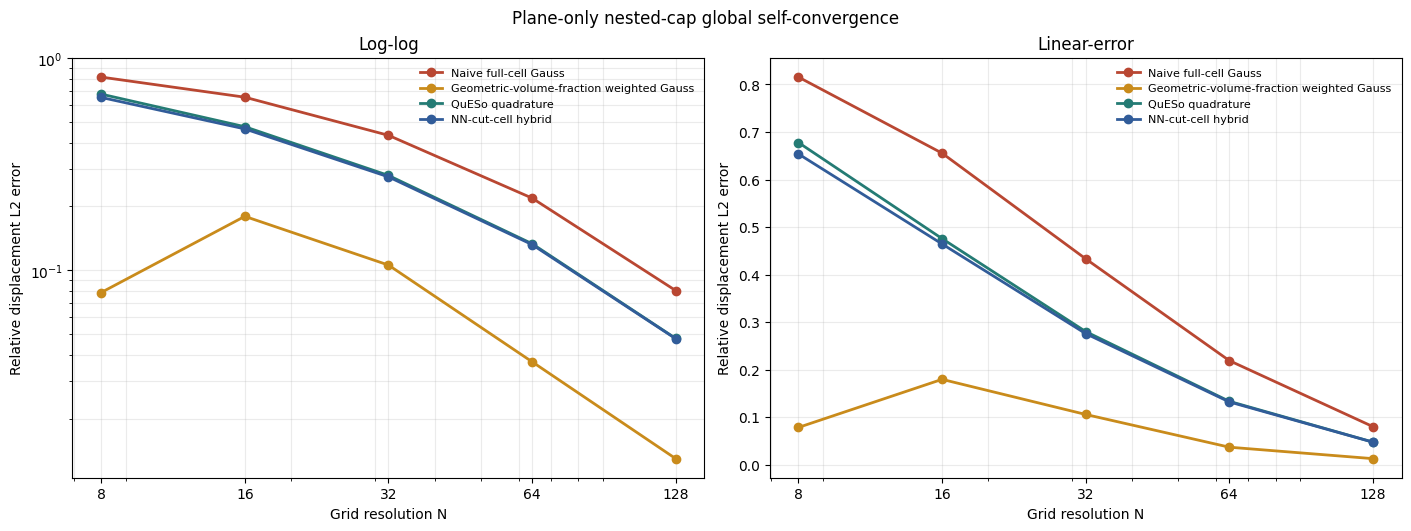

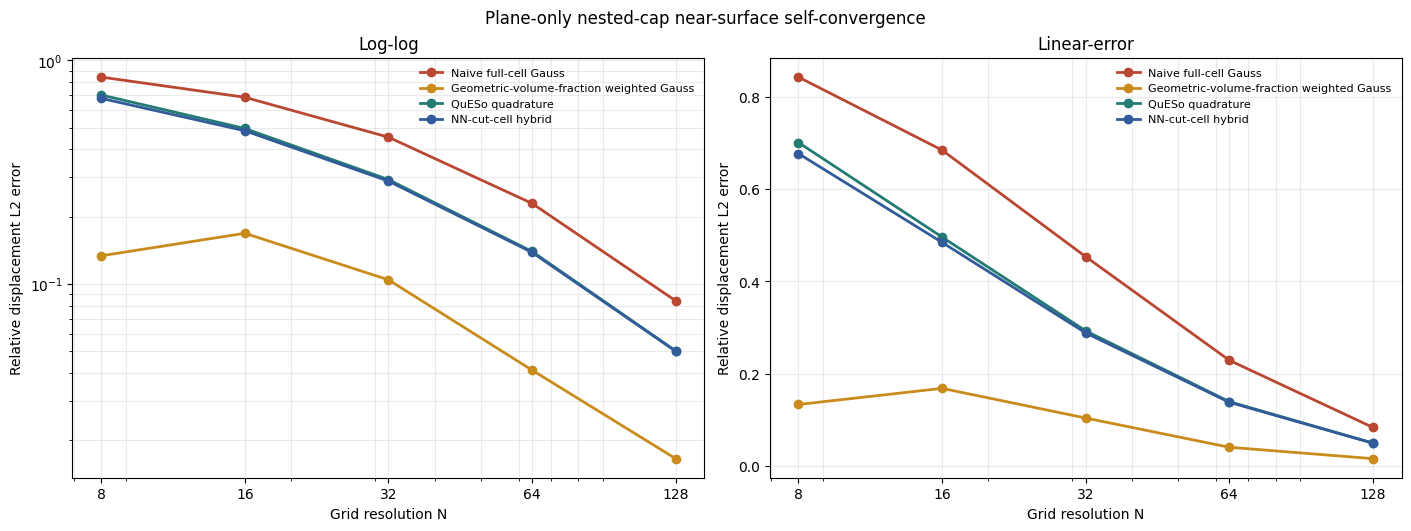


global fitted orders:
  naive   : p=0.827
  weighted: p=0.748
  queso   : p=0.949
  nn      : p=0.937

surface fitted orders:
  naive   : p=0.822
  weighted: p=0.806
  queso   : p=0.943
  nn      : p=0.932
Saved CSVs and graphs in C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence\planar_cap_plane_hard_constraints.


In [ ]:
# Evaluate the completed plane-only benchmark against each framework's own 256^3 field.
import matplotlib.pyplot as plt

PLANAR_CAP_REFERENCE_RESOLUTION = 256
PLANAR_CAP_COMPARISON_RESOLUTIONS = (8, 16, 32, 64, 128)
PLANAR_CAP_RESULTS_PATH = PLANAR_CAP_OUTPUT_DIR / 'four_framework_plane_cap_256_self_reference.csv'
PLANAR_CAP_SURFACE_RESULTS_PATH = PLANAR_CAP_OUTPUT_DIR / 'four_framework_plane_cap_256_self_reference_surface_band.csv'
PLANAR_CAP_FIGURE_PATH = PLANAR_CAP_OUTPUT_DIR / 'four_framework_plane_cap_256_self_reference.png'
PLANAR_CAP_SURFACE_FIGURE_PATH = PLANAR_CAP_OUTPUT_DIR / 'four_framework_plane_cap_256_self_reference_surface_band.png'


def interpolate_plane_cap_solution(solution_u, coarse_resolution):
    field = torch.as_tensor(solution_u, dtype=torch.float64).reshape((coarse_resolution + 1,) * 3 + (3,))
    return torch.nn.functional.interpolate(
        field.permute(3, 0, 1, 2).unsqueeze(0),
        size=(PLANAR_CAP_REFERENCE_RESOLUTION + 1,) * 3,
        mode='trilinear',
        align_corners=True,
    ).squeeze(0).permute(1, 2, 3, 0).reshape(-1, 3).numpy()


def plane_cap_reference_node_mask(active_cells, coarse_resolution):
    scale = PLANAR_CAP_REFERENCE_RESOLUTION // coarse_resolution
    cells = np.zeros((coarse_resolution,) * 3, dtype=bool)
    cells.reshape(-1)[np.asarray(active_cells, dtype=np.int64)] = True
    fine_cells = np.repeat(np.repeat(np.repeat(cells, scale, axis=0), scale, axis=1), scale, axis=2)
    nodes = np.zeros((PLANAR_CAP_REFERENCE_RESOLUTION + 1,) * 3, dtype=bool)
    for ox, oy, oz in ((0, 0, 0), (1, 0, 0), (1, 1, 0), (0, 1, 0), (0, 0, 1), (1, 0, 1), (1, 1, 1), (0, 1, 1)):
        nodes[ox:ox + PLANAR_CAP_REFERENCE_RESOLUTION, oy:oy + PLANAR_CAP_REFERENCE_RESOLUTION, oz:oz + PLANAR_CAP_REFERENCE_RESOLUTION] |= fine_cells
    return nodes.reshape(-1)


def plane_cap_surface_mask():
    coordinates = np.linspace(-9.0, 9.0, PLANAR_CAP_REFERENCE_RESOLUTION + 1, dtype=np.float64)
    x, y, z = np.meshgrid(coordinates, coordinates, coordinates, indexing='ij')
    return (np.abs(np.sqrt(x * x + y * y + z * z) - 7.5) <= 2.0 * 18.0 / PLANAR_CAP_REFERENCE_RESOLUTION).reshape(-1)


surface_mask = plane_cap_surface_mask()
global_rows, surface_rows = [], []
for framework, label in FRAMEWORKS.items():
    with np.load(planar_cap_solution_path(framework, PLANAR_CAP_REFERENCE_RESOLUTION), allow_pickle=True) as reference:
        reference_u = reference['u_nodes']
        reference_nodes = plane_cap_reference_node_mask(reference['active_cells'], PLANAR_CAP_REFERENCE_RESOLUTION)
    for resolution in PLANAR_CAP_COMPARISON_RESOLUTIONS:
        with np.load(planar_cap_solution_path(framework, resolution), allow_pickle=True) as coarse:
            interpolated = interpolate_plane_cap_solution(coarse['u_nodes'], resolution)
            comparison_nodes = reference_nodes & plane_cap_reference_node_mask(coarse['active_cells'], resolution)
            reference_values = reference_u[comparison_nodes]
            difference = interpolated[comparison_nodes] - reference_values
            reference_cell_volume = (18.0 / PLANAR_CAP_REFERENCE_RESOLUTION) ** 3
            absolute_l2_error = np.sqrt(reference_cell_volume * np.sum(difference * difference))
            global_error = np.linalg.norm(difference) / max(np.linalg.norm(reference_values), np.finfo(np.float64).tiny)
            reference_magnitudes = np.linalg.norm(reference_values, axis=1)
            local_reference_floor = max(float(reference_magnitudes.max()) * 1.0e-12, np.finfo(np.float64).tiny)
            valid_local_reference = reference_magnitudes > local_reference_floor
            nodewise_relative_error = np.linalg.norm(difference[valid_local_reference], axis=1) / reference_magnitudes[valid_local_reference]
            rms_nodewise_relative_error = np.sqrt(np.mean(nodewise_relative_error * nodewise_relative_error))
            surface_nodes = comparison_nodes & surface_mask
            surface_reference_values = reference_u[surface_nodes]
            surface_difference = interpolated[surface_nodes] - surface_reference_values
            surface_absolute_l2_error = np.sqrt(reference_cell_volume * np.sum(surface_difference * surface_difference))
            surface_error = np.linalg.norm(surface_difference) / max(np.linalg.norm(surface_reference_values), np.finfo(np.float64).tiny)
            surface_reference_magnitudes = np.linalg.norm(surface_reference_values, axis=1)
            surface_local_reference_floor = max(float(surface_reference_magnitudes.max()) * 1.0e-12, np.finfo(np.float64).tiny)
            valid_surface_local_reference = surface_reference_magnitudes > surface_local_reference_floor
            surface_nodewise_relative_error = np.linalg.norm(surface_difference[valid_surface_local_reference], axis=1) / surface_reference_magnitudes[valid_surface_local_reference]
            surface_rms_nodewise_relative_error = np.sqrt(np.mean(surface_nodewise_relative_error * surface_nodewise_relative_error))
            base_row = {
                'framework': framework, 'framework_label': label, 'reference_framework': framework,
                'resolution': resolution, 'reference_resolution': PLANAR_CAP_REFERENCE_RESOLUTION,
                'solver_iterations': int(coarse['solver_info'][0]['iters']), 'solver_residual': float(coarse['solver_info'][0]['residual']),
            }
            global_rows.append({**base_row, 'comparison_nodes': int(comparison_nodes.sum()), 'nodewise_relative_nodes': int(valid_local_reference.sum()), 'absolute_l2_error': absolute_l2_error, 'relative_l2_error': global_error, 'rms_nodewise_relative_error': rms_nodewise_relative_error})
            surface_rows.append({**base_row, 'comparison_nodes': int(surface_nodes.sum()), 'nodewise_relative_nodes': int(valid_surface_local_reference.sum()), 'absolute_l2_error': surface_absolute_l2_error, 'relative_l2_error': surface_error, 'rms_nodewise_relative_error': surface_rms_nodewise_relative_error})
            print(f'{framework:8s} {resolution:3d}^3: global absolute={absolute_l2_error:.4e}, relative={global_error:.4e}, nodewise RMS={rms_nodewise_relative_error:.4e}; surface nodewise RMS={surface_rms_nodewise_relative_error:.4e}')
        del interpolated, difference, surface_difference
        gc.collect()

global_results = pd.DataFrame(global_rows).sort_values(['framework', 'resolution'])
surface_results = pd.DataFrame(surface_rows).sort_values(['framework', 'resolution'])
global_results.to_csv(PLANAR_CAP_RESULTS_PATH, index=False)
surface_results.to_csv(PLANAR_CAP_SURFACE_RESULTS_PATH, index=False)

for results, title, figure_path in (
    (global_results, 'Plane-only nested-cap global self-convergence', PLANAR_CAP_FIGURE_PATH),
    (surface_results, 'Plane-only nested-cap near-surface self-convergence', PLANAR_CAP_SURFACE_FIGURE_PATH),
):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
    for framework, label in FRAMEWORKS.items():
        curve = results[results['framework'] == framework].sort_values('resolution')
        axes[0].loglog(curve['resolution'], curve['absolute_l2_error'], marker='o', linewidth=2, color=FRAMEWORK_COLORS[framework], label=label)
        axes[1].semilogx(curve['resolution'], curve['absolute_l2_error'], marker='o', linewidth=2, color=FRAMEWORK_COLORS[framework], label=label)
    for axis in axes:
        axis.set_xticks(PLANAR_CAP_COMPARISON_RESOLUTIONS)
        axis.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        axis.grid(True, which='both', alpha=0.25)
        axis.legend(frameon=False, fontsize=8)
        axis.set(xlabel='Grid resolution N', ylabel='Absolute displacement L2 error')
    axes[0].set_title('Log-log')
    axes[1].set_title('Linear-error')
    fig.suptitle(title + ': absolute field error')
    absolute_figure_path = figure_path.with_name(figure_path.stem + '_absolute_l2.png')
    fig.savefig(absolute_figure_path, dpi=180, bbox_inches='tight')
    plt.show()

    nodewise_figure, nodewise_axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
    for framework, label in FRAMEWORKS.items():
        curve = results[results['framework'] == framework].sort_values('resolution')
        nodewise_axes[0].loglog(curve['resolution'], curve['rms_nodewise_relative_error'], marker='o', linewidth=2, color=FRAMEWORK_COLORS[framework], label=label)
        nodewise_axes[1].semilogx(curve['resolution'], curve['rms_nodewise_relative_error'], marker='o', linewidth=2, color=FRAMEWORK_COLORS[framework], label=label)
    for axis in nodewise_axes:
        axis.set_xticks(PLANAR_CAP_COMPARISON_RESOLUTIONS)
        axis.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        axis.grid(True, which='both', alpha=0.25)
        axis.legend(frameon=False, fontsize=8)
        axis.set(xlabel='Grid resolution N', ylabel='RMS nodewise relative displacement error')
    nodewise_axes[0].set_title('Log-log')
    nodewise_axes[1].set_title('Linear-error')
    nodewise_figure.suptitle(title + ': local-reference normalized field error')
    nodewise_figure_path = figure_path.with_name(figure_path.stem + '_nodewise_relative.png')
    nodewise_figure.savefig(nodewise_figure_path, dpi=180, bbox_inches='tight')
    plt.show()

for results, name in ((global_results, 'global'), (surface_results, 'surface')):
    print(f'\n{name} fitted orders:')
    for framework in FRAMEWORKS:
        curve = results[results['framework'] == framework].sort_values('resolution')
        relative_slope, _ = np.polyfit(np.log(curve['resolution']), np.log(curve['relative_l2_error']), 1)
        absolute_slope, _ = np.polyfit(np.log(curve['resolution']), np.log(curve['absolute_l2_error']), 1)
        nodewise_slope, _ = np.polyfit(np.log(curve['resolution']), np.log(curve['rms_nodewise_relative_error']), 1)
        print(f'  {framework:8s}: relative p={-relative_slope:.3f}; absolute p={-absolute_slope:.3f}; nodewise-relative p={-nodewise_slope:.3f}')
print(f'Saved CSVs and graphs in {PLANAR_CAP_OUTPUT_DIR}.')

In [3]:
# Consecutive-pair refinement orders: e(N) / e(2N) = 2^p.
PLANAR_CAP_OUTPUT_DIR = OUTPUT_DIR / 'planar_cap_plane_hard_constraints'
pairwise_order_rows = []
for metric, filename in (
    ('global', 'four_framework_plane_cap_256_self_reference.csv'),
    ('surface', 'four_framework_plane_cap_256_self_reference_surface_band.csv'),
):
    results = pd.read_csv(PLANAR_CAP_OUTPUT_DIR / filename)
    for framework, curve in results.groupby('framework', sort=False):
        curve = curve.sort_values('resolution').reset_index(drop=True)
        for index in range(len(curve) - 1):
            coarse = curve.iloc[index]
            fine = curve.iloc[index + 1]
            refinement_ratio = fine['resolution'] / coarse['resolution']
            order = np.log(coarse['relative_l2_error'] / fine['relative_l2_error']) / np.log(refinement_ratio)
            pairwise_order_rows.append({
                'metric': metric,
                'framework': framework,
                'framework_label': coarse['framework_label'],
                'coarse_resolution': int(coarse['resolution']),
                'fine_resolution': int(fine['resolution']),
                'coarse_error': coarse['relative_l2_error'],
                'fine_error': fine['relative_l2_error'],
                'consecutive_order': order,
            })

pairwise_orders = pd.DataFrame(pairwise_order_rows)
PAIRWISE_ORDERS_PATH = PLANAR_CAP_OUTPUT_DIR / 'four_framework_plane_cap_256_consecutive_orders.csv'
pairwise_orders.to_csv(PAIRWISE_ORDERS_PATH, index=False)
for metric in ('global', 'surface'):
    print(f'\n{metric} consecutive orders:')
    display(pairwise_orders[pairwise_orders['metric'] == metric][[
        'framework_label', 'coarse_resolution', 'fine_resolution', 'consecutive_order',
    ]])
print(f'Saved consecutive orders to {PAIRWISE_ORDERS_PATH.name}.')


global consecutive orders:


,framework_label,coarse_resolution,fine_resolution,consecutive_order
0,Naive full-cell Gauss,8,16,0.315151
1,Naive full-cell Gauss,16,32,0.597374
2,Naive full-cell Gauss,32,64,0.983523
3,Naive full-cell Gauss,64,128,1.448785
4,NN-cut-cell hybrid,8,16,0.493267
5,NN-cut-cell hybrid,16,32,0.751358
6,NN-cut-cell hybrid,32,64,1.061067
7,NN-cut-cell hybrid,64,128,1.474521
8,QuESo quadrature,8,16,0.510711
9,QuESo quadrature,16,32,0.763559



surface consecutive orders:


,framework_label,coarse_resolution,fine_resolution,consecutive_order
16,Naive full-cell Gauss,8,16,0.299825
17,Naive full-cell Gauss,16,32,0.592958
18,Naive full-cell Gauss,32,64,0.983695
19,Naive full-cell Gauss,64,128,1.447034
20,NN-cut-cell hybrid,8,16,0.481845
21,NN-cut-cell hybrid,16,32,0.747343
22,NN-cut-cell hybrid,32,64,1.059119
23,NN-cut-cell hybrid,64,128,1.468036
24,QuESo quadrature,8,16,0.498143
25,QuESo quadrature,16,32,0.759158


Saved consecutive orders to four_framework_plane_cap_256_consecutive_orders.csv.


In [5]:
# Audit the four global stiffness operators on one identical small planar-cap problem.
# Run after the planar-cap setup cells that define build_hard_constraint_problem(),
# hard_constraint_cut_matrices(), and planar_cap_hard_constraint_dofs().
MATRIX_AUDIT_RESOLUTION = 16
MATRIX_AUDIT_PATH = PLANAR_CAP_OUTPUT_DIR / f"four_framework_matrix_audit_{MATRIX_AUDIT_RESOLUTION}cubed.csv"

required_matrix_audit_helpers = (
    "build_hard_constraint_problem",
    "hard_constraint_cut_matrices",
    "planar_cap_hard_constraint_dofs",
)
missing_matrix_audit_helpers = [name for name in required_matrix_audit_helpers if name not in globals()]
if missing_matrix_audit_helpers:
    raise RuntimeError(
        "Run the planar-cap problem setup cells first; missing: "
        + ", ".join(missing_matrix_audit_helpers)
    )

case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions = build_hard_constraint_problem(
    MATRIX_AUDIT_RESOLUTION
)
constrained_dofs, cap_start = planar_cap_hard_constraint_dofs(case, active)

nn_engine = None
if "nn" in FRAMEWORKS:
    nn_engine = load_nn_engine(
        checkpoint_path=NN_CHECKPOINT,
        device="cuda" if torch.cuda.is_available() else "cpu",
        dtype="float32",
    )

operators = {}
for framework in FRAMEWORKS:
    cut_matrices = hard_constraint_cut_matrices(
        framework,
        case,
        full_ke,
        queso_cut_ke,
        cut_indices,
        fractions,
        nn_engine,
    )
    operators[framework] = StructuredCompressedMatrixFreeElasticityOperator(
        full_ke,
        full_indices,
        cut_matrices,
        cut_indices,
        tuple(case.grid.resolution),
        None,
        element_batch_size=32768,
        slab_cells=32,
        constrained_dofs=constrained_dofs,
    )
    del cut_matrices

if nn_engine is not None:
    del nn_engine
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

probe_operator = operators["queso"]
torch.manual_seed(20260812)
probe_x = torch.randn(3 * probe_operator.node_count, dtype=probe_operator.dtype, device=probe_operator.device)
probe_y = torch.randn_like(probe_x)
probe_x[probe_operator.constrained_dofs] = 0.0
probe_y[probe_operator.constrained_dofs] = 0.0

operator_actions = {name: operator.matvec(probe_x) for name, operator in operators.items()}
energy = {name: float(torch.dot(probe_x, action).detach().cpu()) for name, action in operator_actions.items()}
symmetry_defect = {
    name: float(
        torch.abs(torch.dot(probe_x, operator.matvec(probe_y)) - torch.dot(probe_y, action))
        / torch.maximum(torch.abs(torch.dot(probe_x, action)), torch.tensor(1.0, dtype=operator.dtype, device=operator.device))
    )
    for name, (operator, action) in {
        name: (operators[name], operator_actions[name]) for name in FRAMEWORKS
    }.items()
}

matrix_audit_rows = []
for left_name in FRAMEWORKS:
    for right_name in FRAMEWORKS:
        if left_name >= right_name:
            continue
        left_action = operator_actions[left_name]
        right_action = operator_actions[right_name]
        relative_action_difference = float(
            torch.linalg.vector_norm(left_action - right_action)
            / torch.linalg.vector_norm(right_action).clamp_min(torch.finfo(right_action.dtype).tiny)
        )
        energy_ratio = energy[left_name] / energy[right_name]
        matrix_audit_rows.append({
            "resolution": MATRIX_AUDIT_RESOLUTION,
            "cap_start": cap_start,
            "left_framework": left_name,
            "right_framework": right_name,
            "relative_action_difference": relative_action_difference,
            "left_energy": energy[left_name],
            "right_energy": energy[right_name],
            "energy_ratio": energy_ratio,
            "left_symmetry_defect": symmetry_defect[left_name],
            "right_symmetry_defect": symmetry_defect[right_name],
        })

matrix_audit = pd.DataFrame(matrix_audit_rows).sort_values("relative_action_difference")
matrix_audit.to_csv(MATRIX_AUDIT_PATH, index=False)
print(f"Matrix audit at {MATRIX_AUDIT_RESOLUTION}^3 with {len(cut_indices):,} cut cells and planar cap z={cap_start:.4f}")
display(matrix_audit)

for operator in operators.values():
    del operator
del operators, operator_actions, case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()
print(f"Saved operator-action and energy comparisons to {MATRIX_AUDIT_PATH}")

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0029 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0294 seconds.
[CASE BUILD] QuESo settings write took 0.0011 seconds.
[CASE BUILD] Reusing 21,469 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0140 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.0497 seconds.
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 2/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 4/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 6/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 8/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 10/16 [0.0s]
[

C:\Users\z0058p1u\Documents\code\clean_simulation\internal_fem_kernel\runtime\common.py:30: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  return torch.as_tensor(x, dtype=dtype, device=device)
C:\Users\z0058p1u\Documents\code\clean_simulation\nn_runtime.py:44: RuntimeWarning: Skipping torch.set_num_interop_threads after runtime init (Error: cannot set number of interop threads after parallel work has started or set_num_interop_threads called).
  return FastCutCellInference.from_checkpoint(ckpt, options=options)


8


C:\Users\z0058p1u\Documents\code\clean_simulation\internal_nn_runtime\cutcell_ml\model.py:920: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  rows, cols = torch.triu_indices(


Matrix audit at 16^3 with 800 cut cells and planar cap z=6.7500


,resolution,cap_start,left_framework,right_framework,relative_action_difference,left_energy,right_energy,energy_ratio,left_symmetry_defect,right_symmetry_defect
5,16,6.75,nn,queso,0.016127,7.471676e+09,7.557284e+09,0.988672,2.193788e-17,2.168938e-17
1,16,6.75,naive,queso,0.398196,1.006292e+10,7.557284e+09,1.331552,2.665438e-17,2.168938e-17
2,16,6.75,naive,nn,0.412602,1.006292e+10,7.471676e+09,1.346809,2.665438e-17,2.193788e-17
4,16,6.75,nn,weighted,0.462586,7.471676e+09,5.296407e+09,1.410707,2.193788e-17,4.501515e-17
3,16,6.75,queso,weighted,0.477324,7.557284e+09,5.296407e+09,1.426870,2.168938e-17,4.501515e-17
0,16,6.75,naive,weighted,0.816064,1.006292e+10,5.296407e+09,1.899952,2.665438e-17,4.501515e-17


Saved operator-action and energy comparisons to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence\planar_cap_plane_hard_constraints\four_framework_matrix_audit_16cubed.csv


In [9]:
# Compare cut-cell matrices at identical structured-cell coordinates against QuESo.
# This isolates the cut-cell approximation from the global assembly and solve.
LOCAL_MATRIX_AUDIT_RESOLUTION = 16
LOCAL_MATRIX_AUDIT_PATH = PLANAR_CAP_OUTPUT_DIR / f"four_framework_local_matrix_audit_{LOCAL_MATRIX_AUDIT_RESOLUTION}cubed.csv"

required_local_matrix_audit_helpers = (
    "build_hard_constraint_problem",
    "hard_constraint_cut_matrices",
)
missing_local_matrix_audit_helpers = [name for name in required_local_matrix_audit_helpers if name not in globals()]
if missing_local_matrix_audit_helpers:
    raise RuntimeError(
        "Run the planar-cap problem setup cells first; missing: "
        + ", ".join(missing_local_matrix_audit_helpers)
    )

case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions = build_hard_constraint_problem(
    LOCAL_MATRIX_AUDIT_RESOLUTION
)
nn_engine = load_nn_engine(
    checkpoint_path=NN_CHECKPOINT,
    device="cuda" if torch.cuda.is_available() else "cpu",
    dtype="float32",
)
cut_matrices_by_framework = {
    "queso": queso_cut_ke.to(dtype=torch.float64, device="cpu"),
    "naive": hard_constraint_cut_matrices(
        "naive", case, full_ke, queso_cut_ke, cut_indices, fractions
    ).to(dtype=torch.float64, device="cpu"),
    "weighted": hard_constraint_cut_matrices(
        "weighted", case, full_ke, queso_cut_ke, cut_indices, fractions
    ).to(dtype=torch.float64, device="cpu"),
    "nn": hard_constraint_cut_matrices(
        "nn", case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine
    ).to(dtype=torch.float64, device="cpu"),
}
del nn_engine
if torch.cuda.is_available():
    torch.cuda.empty_cache()

reference_norm = torch.linalg.matrix_norm(cut_matrices_by_framework["queso"], ord="fro")
reference_norm = reference_norm.clamp_min(torch.finfo(torch.float64).tiny)
local_matrix_rows = []
for framework in ("naive", "weighted", "nn"):
    difference = cut_matrices_by_framework[framework] - cut_matrices_by_framework["queso"]
    relative_frobenius_error = torch.linalg.matrix_norm(difference, ord="fro") / reference_norm
    symmetry_defect = torch.linalg.matrix_norm(
        cut_matrices_by_framework[framework] - cut_matrices_by_framework[framework].transpose(1, 2),
        ord="fro",
    ) / torch.linalg.matrix_norm(cut_matrices_by_framework[framework], ord="fro").clamp_min(
        torch.finfo(torch.float64).tiny
    )
    for index, cell_id in enumerate(cut_indices.cpu().numpy()):
        local_matrix_rows.append({
            "resolution": LOCAL_MATRIX_AUDIT_RESOLUTION,
            "cell_id": int(cell_id),
            "framework": framework,
            "physical_volume_fraction": float(fractions[index]),
            "relative_frobenius_error_vs_queso": float(relative_frobenius_error[index]),
            "max_absolute_entry_error_vs_queso": float(difference[index].abs().max()),
            "relative_symmetry_defect": float(symmetry_defect[index]),
        })

local_matrix_audit = pd.DataFrame(local_matrix_rows)
local_matrix_audit.to_csv(LOCAL_MATRIX_AUDIT_PATH, index=False)
local_matrix_summary = (
    local_matrix_audit.groupby("framework", sort=False)
    .agg(
        cut_cells=("cell_id", "size"),
        median_relative_frobenius_error=("relative_frobenius_error_vs_queso", "median"),
        p95_relative_frobenius_error=("relative_frobenius_error_vs_queso", lambda values: values.quantile(0.95)),
        max_relative_frobenius_error=("relative_frobenius_error_vs_queso", "max"),
        median_relative_symmetry_defect=("relative_symmetry_defect", "median"),
        max_relative_symmetry_defect=("relative_symmetry_defect", "max"),
    )
    .reset_index()
)
print(f"Local matrix audit at {LOCAL_MATRIX_AUDIT_RESOLUTION}^3 on {len(cut_indices):,} identical cut-cell coordinates")
display(local_matrix_summary)

for name in tuple(cut_matrices_by_framework):
    del cut_matrices_by_framework[name]
del case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"Saved per-cell matrix errors to {LOCAL_MATRIX_AUDIT_PATH}")

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0281 seconds.
[CASE BUILD] QuESo settings write took 0.0008 seconds.
[CASE BUILD] Reusing 21,469 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0120 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.0433 seconds.
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 2/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 4/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 6/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 8/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 10/16 [0.0s]
[

: 